[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/complexluise/laboratorio-cocreacion-empalme-colombia/blob/main/analisis_de_datos/sesion2-solucion.ipynb)

# Sesión 2 · Análisis de redes: instrumentos y políticas de CTeI — **solución**

Este cuaderno analiza la red que sacamos de los informes de empalme (lo que un gobierno le entrega al siguiente, 2018–2022 y 2022–2026). La miramos de dos formas:

1. Qué instrumento sirve a qué política: la **red bipartita**, con 93 instrumentos y 14 políticas.
2. Qué instrumentos comparten políticas, y qué políticas comparten instrumentos.

Es la versión resuelta del ejercicio (`sesion2-ejercicio.ipynb`).

Advertencia: la red la hizo la IA y nadie la ha revisado completa. Los resultados describen la red, no a los gobiernos. Las interpretaciones de la última sección son inferencias.

## 1. Configuración y carga de datos

Usamos la hoja `Instrumentos` del Excel de la red. Cada instrumento se conecta a las políticas de la columna "Políticas a las que sirve".

**En Colab:** al correr la celda siguiente aparece un botón para subir `red-ciencia-tecnologia.xlsx`. Si no lo tenemos, pulsamos *Cancelar* y el cuaderno lo descarga del sitio del laboratorio.

In [1]:
import sys
import urllib.request
from pathlib import Path

ARCHIVO = "red-ciencia-tecnologia.xlsx"
URL_DATOS = f"https://complexluise.github.io/laboratorio-cocreacion-empalme-colombia/{ARCHIVO}"
EN_COLAB = "google.colab" in sys.modules

RUTA = Path(ARCHIVO)
if EN_COLAB:
    from google.colab import files
    try:
        subidos = files.upload()
    except Exception:
        subidos = {}
    if subidos:
        RUTA = Path(next(iter(subidos)))
elif not RUTA.exists() and (Path("analisis_de_datos") / ARCHIVO).exists():
    RUTA = Path("analisis_de_datos") / ARCHIVO

if not RUTA.exists():
    print("No se subió el archivo: lo descargo del sitio del laboratorio…")
    urllib.request.urlretrieve(URL_DATOS, RUTA)

SALIDA = RUTA.parent / "salidas"
SALIDA.mkdir(exist_ok=True)
print("Datos:", RUTA, "· Salidas en:", SALIDA)

Datos: red-ciencia-tecnologia.xlsx · Salidas en: salidas


In [2]:
import numpy as np
import pandas as pd
import openpyxl
import networkx as nx
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from networkx.algorithms import bipartite as bp

print("pandas", pd.__version__, "· networkx", nx.__version__, "· matplotlib", matplotlib.__version__)
SEED = 42

# Estilo tipo artículo: serif, fondo blanco, sin marco superior ni derecho, ejes sobrios.
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif", "Times New Roman", "Liberation Serif"],
    "font.size": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 0.6,
    "axes.titlesize": 10,
    "axes.titleweight": "normal",
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.frameon": False,
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})
PALETA = ["#4C6A92", "#B5651D", "#5B7F4F", "#8E5572", "#A69A3A"]


def corto(texto, n=44):
    """Etiqueta corta para las figuras."""
    t = texto.split(" (")[0].split(" - ")[0].strip()
    return t if len(t) <= n else t[: n - 1] + "…"


def revisar(condicion, pista):
    """Celda de verificación: confirma el resultado o da una pista."""
    if condicion:
        print("✅ ¡Bien! Puedes seguir.")
    else:
        raise AssertionError(f"Todavía no. Pista: {pista}")

pandas 3.1.1 · networkx 3.7 · matplotlib 3.11.2


In [3]:
wb = openpyxl.load_workbook(RUTA, read_only=True, data_only=True)
filas = [r for r in list(wb["Instrumentos"].iter_rows(values_only=True))[1:] if r[0]]

insts = pd.DataFrame([
    {
        "instrumento": r[0].strip(),
        "nato": r[1],
        "modo": r[2],
        "pres_1822": r[3],
        "pres_2226": r[4],
        "politicas": [p.strip() for p in (r[5] or "").split(";") if p.strip()],
    }
    for r in filas
])
print(f"{len(insts)} instrumentos cargados")
insts.head(3)

93 instrumentos cargados


,instrumento,nato,modo,pres_1822,pres_2226,politicas
0,Resolución 1452 de 2024 (adopción PIIOM),autoridad,estratificación,—,logrado,"[Orientación estratégica de la CTeI, Bioeconom..."
1,Metodología nacional de seis etapas de las PIIOM,nodalidad,estratificación,—,logrado,[Orientación estratégica de la CTeI]
2,Convocatorias y mecanismos propios de cada Mis...,tesoro,estratificación,—,logrado,"[Orientación estratégica de la CTeI, Bioeconom..."


## 2. Construcción de la red bipartita

Los nodos de un lado son instrumentos y los del otro, políticas. Una arista indica que el instrumento sirve a esa política. No hay aristas dentro de un mismo tipo de nodo.

In [4]:
B = nx.Graph()
for _, row in insts.iterrows():
    B.add_node(row.instrumento, bipartite=0, nato=row.nato, modo=row.modo)
    for p in set(row.politicas):
        B.add_node(p, bipartite=1)
        B.add_edge(row.instrumento, p)

INST = set(insts.instrumento)
POL = set(p for ps in insts.politicas for p in ps)

resumen = pd.Series({
    "instrumentos": len(INST),
    "políticas": len(POL),
    "aristas": B.number_of_edges(),
    "densidad (inst × pol)": round(bp.density(B, INST), 3),
    "componentes conexas": nx.number_connected_components(B),
    "instrumentos sin política": sum(1 for n in INST if B.degree(n) == 0),
})
resumen

instrumentos                  93.000
políticas                     14.000
aristas                      201.000
densidad (inst × pol)          0.154
componentes conexas            1.000
instrumentos sin política      0.000
dtype: float64

In [5]:
revisar(
    B.number_of_edges() == 201 and resumen["densidad (inst × pol)"] == 0.154,
    "cada arista une un instrumento con una política; la densidad se calcula sobre el conjunto de instrumentos (INST).",
)

✅ ¡Bien! Puedes seguir.


## 3. Distribución de instrumentos

Antes de la red conviene ver la composición del archivo: el *modo de cambio* (si el instrumento siguió, cambió o desapareció entre gobiernos) y el *tipo NATO* (si el Estado actúa con información, autoridad, dinero u organización). Las definiciones están en el glosario del sitio.

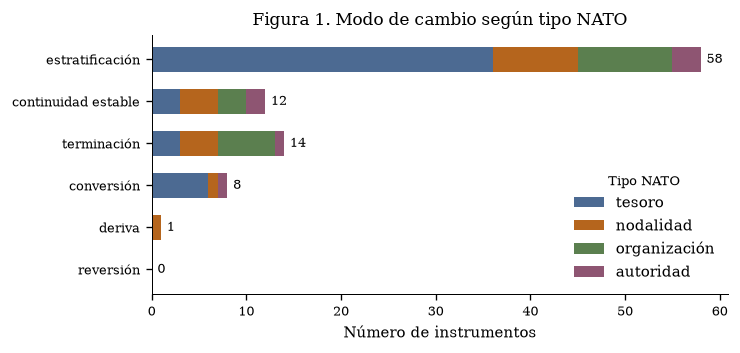

In [6]:
orden_modo = ["estratificación", "continuidad estable", "terminación", "conversión", "deriva", "reversión"]
orden_nato = ["tesoro", "nodalidad", "organización", "autoridad"]

modos = insts.modo.value_counts().reindex(orden_modo, fill_value=0)
cruce = pd.crosstab(insts.modo, insts.nato).reindex(index=orden_modo, columns=orden_nato, fill_value=0)

fig, ax = plt.subplots(figsize=(6.2, 2.8))
izq = np.zeros(len(orden_modo))
for tipo, color in zip(orden_nato, PALETA):
    ax.barh(orden_modo, cruce[tipo].values, left=izq, color=color, label=tipo, height=0.6)
    izq += cruce[tipo].values
for y, total in enumerate(modos.values):
    ax.text(total + 0.6, y, str(total), va="center", fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("Número de instrumentos")
ax.set_title("Figura 1. Modo de cambio según tipo NATO")
ax.legend(title="Tipo NATO", title_fontsize=8, loc="lower right")
fig.savefig(SALIDA / "fig1_modo_cambio.png")
plt.show()

In [7]:
revisar(modos.sum() == 93, "hay que contar cuántas veces aparece cada modo de cambio (value_counts).")

✅ ¡Bien! Puedes seguir.


La estratificación domina con 58 de 93 instrumentos (62 %). Esto es coherente con la metodología, pero también depende de que el informe anterior no mencione un instrumento. Si un programa cambió de nombre, la IA que leyó los informes pudo contarlo como nuevo. Este punto se revisa en la última sección.

## 4. Grado de las políticas

El grado de una política es el número de instrumentos que la sirven.

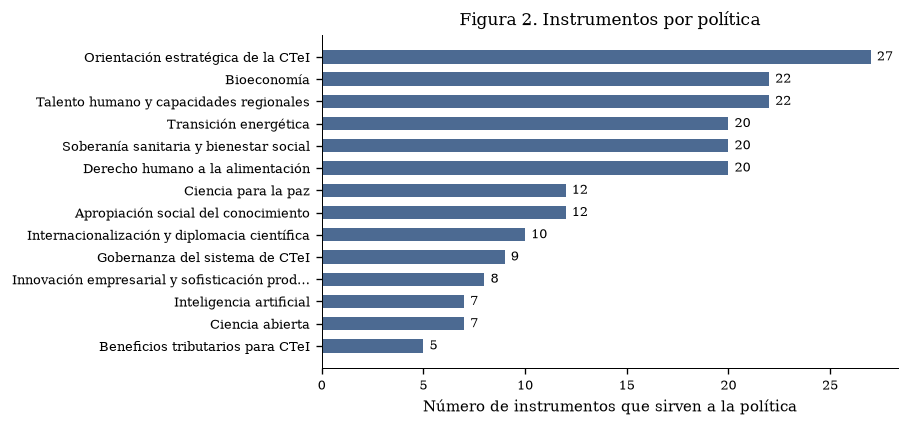

In [8]:
grado_pol = pd.Series({p: B.degree(p) for p in POL}).sort_values()

fig, ax = plt.subplots(figsize=(6.2, 3.6))
ax.barh([corto(p) for p in grado_pol.index], grado_pol.values, color=PALETA[0], height=0.6)
for y, v in enumerate(grado_pol.values):
    ax.text(v + 0.3, y, str(v), va="center", fontsize=8)
ax.set_xlabel("Número de instrumentos que sirven a la política")
ax.set_title("Figura 2. Instrumentos por política")
fig.savefig(SALIDA / "fig2_grado_politicas.png")
plt.show()

In [9]:
revisar(grado_pol.max() == 27 and grado_pol.sum() == 201, "el grado de un nodo se obtiene con B.degree(nodo).")

✅ ¡Bien! Puedes seguir.


Orientación estratégica concentra 27 instrumentos y funciona como paraguas. Talento, Bioeconomía, Soberanía sanitaria, DHA y Transición energética tienen entre 20 y 22. Beneficios tributarios es la política con menos instrumentos, con 5.

## 5. Red bipartita

Instrumentos a la izquierda, coloreados por tipo NATO; políticas a la derecha, como cuadrados. Cuantas más conexiones, más grande el nodo. Los seis instrumentos más conectados se resaltan, se numeran y se listan al costado.

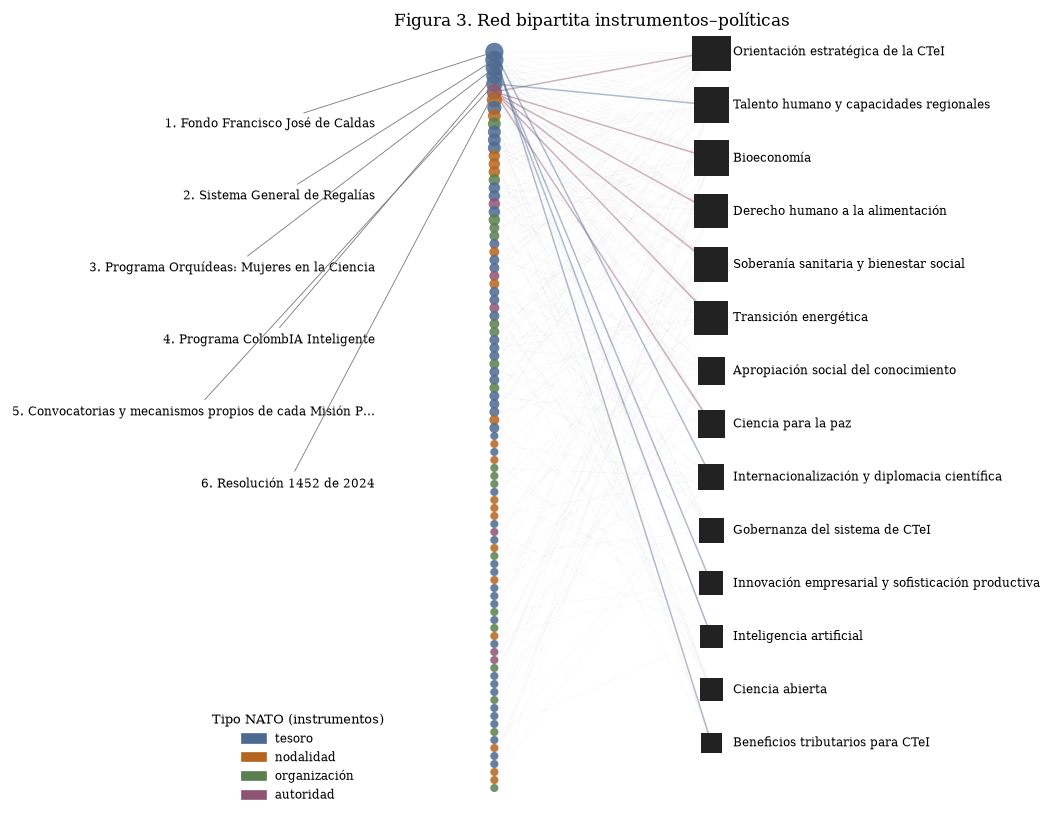

In [10]:
ins_ordenados = sorted(INST, key=lambda n: -B.degree(n))
pol_ordenados = sorted(POL, key=lambda n: -B.degree(n))
top6 = ins_ordenados[:6]

pos = {}
for i, n in enumerate(ins_ordenados):
    pos[n] = (0.0, -i)
paso = len(INST) / len(POL)
for j, n in enumerate(pol_ordenados):
    pos[n] = (1.0, -j * paso)

colores_nato = dict(zip(orden_nato, PALETA))

fig, ax = plt.subplots(figsize=(8.4, 8.4))

# Aristas: todas tenues, y las de los top 6 resaltadas encima
aristas_top = [(u, v) for u, v in B.edges() if u in top6]
aristas_resto = [(u, v) for u, v in B.edges() if u not in top6]
nx.draw_networkx_edges(B, pos, edgelist=aristas_resto, alpha=0.04, width=0.4,
                       edge_color="#444444", ax=ax)
nx.draw_networkx_edges(B, pos, edgelist=aristas_top, alpha=0.45, width=0.9,
                       edge_color=[colores_nato[B.nodes[u]["nato"]] for u, _ in aristas_top],
                       ax=ax)

nx.draw_networkx_nodes(
    B, pos, nodelist=ins_ordenados,
    node_size=[12 + 12 * B.degree(n) for n in ins_ordenados],
    node_color=[colores_nato[B.nodes[n]["nato"]] for n in ins_ordenados],
    alpha=0.85, linewidths=0, ax=ax,
)
nx.draw_networkx_nodes(
    B, pos, nodelist=pol_ordenados,
    node_size=[60 + 18 * B.degree(n) for n in pol_ordenados],
    node_color="#222222", node_shape="s", linewidths=0, ax=ax,
)

# Políticas: etiqueta a la derecha, con margen suficiente
for n in pol_ordenados:
    ax.text(1.10, pos[n][1], corto(n, 60), va="center", fontsize=7)

# Top 6 instrumentos: números sobre el nodo y lista a la izquierda con flecha
for k, n in enumerate(top6, start=1):
    ytxt = -k * 9.0
    ax.annotate(f"{k}. {corto(n, 52)}", xy=pos[n], xytext=(-0.55, ytxt),
                ha="right", va="center", fontsize=7,
                arrowprops=dict(arrowstyle="-", color="#777777", lw=0.5,
                                shrinkA=2, shrinkB=2))

ax.set_xlim(-1.35, 2.25)
ax.set_ylim(-len(INST) - 2, 2)
ax.axis("off")
leyenda = [Patch(color=c, label=t) for t, c in colores_nato.items()]
ax.legend(handles=leyenda, title="Tipo NATO (instrumentos)", title_fontsize=8,
          loc="lower left", fontsize=7)
ax.set_title("Figura 3. Red bipartita instrumentos–políticas")
fig.savefig(SALIDA / "fig3_red_bipartita.png")
plt.show()

La red es conexa y no tiene instrumentos aislados. Tiene 201 aristas y una densidad de 0,154. Cada instrumento sirve en promedio a unas 2,2 políticas, así que la mayoría de las conexiones son de uno o dos.

## 6. Instrumentos más conectados

Para saber qué instrumentos están más conectados, proyectamos la bipartita sobre los instrumentos. Dos instrumentos quedan unidos si comparten al menos una política. El peso de la arista es el número de políticas compartidas.

Calculamos tres medidas por instrumento:

- **Coocurrencia total:** cuántas políticas comparte con los demás instrumentos, sumadas (en redes se llama *grado ponderado*).
- **Intermediación:** cuántas veces el instrumento queda en el camino más corto entre otros dos (en inglés, *betweenness*).
- **Políticas (grado)**: en cuántas políticas participa directamente.

In [11]:
PI = bp.weighted_projected_graph(B, INST)
wdeg = dict(PI.degree(weight="weight"))
btw = nx.betweenness_centrality(PI)  # sin peso

top15 = sorted(wdeg, key=wdeg.get, reverse=True)[:15]
tabla_top = pd.DataFrame({
    "instrumento": [corto(n, 60) for n in top15],
    "políticas": [B.degree(n) for n in top15],
    "coocurrencia": [wdeg[n] for n in top15],
    "intermediación": [round(btw[n], 3) for n in top15],
})
tabla_top

,instrumento,políticas,coocurrencia,intermediación
0,Fondo Francisco José de Caldas,9,149,0.129
1,Sistema General de Regalías,9,149,0.117
2,Programa Orquídeas: Mujeres en la Ciencia,8,142,0.059
3,Convocatorias y mecanismos propios de cada Mis...,7,136,0.037
4,Programa ColombIA Inteligente,7,131,0.056
5,Resolución 1452 de 2024,6,115,0.028
6,PIIOM,6,115,0.028
7,Convocatoria 49 OCAD SGR – Energía sostenible ...,5,94,0.019
8,Programa Jóvenes Investigadores e Innovadores,4,78,0.014
9,Estrategia Jóvenes Salud,4,78,0.014


In [12]:
revisar(
    PI.number_of_nodes() == 93 and max(wdeg.values()) == 149 and round(max(btw.values()), 3) == 0.129,
    "la proyección va sobre INST; el grado ponderado usa weight=\"weight\"; la intermediación es nx.betweenness_centrality.",
)

✅ ¡Bien! Puedes seguir.


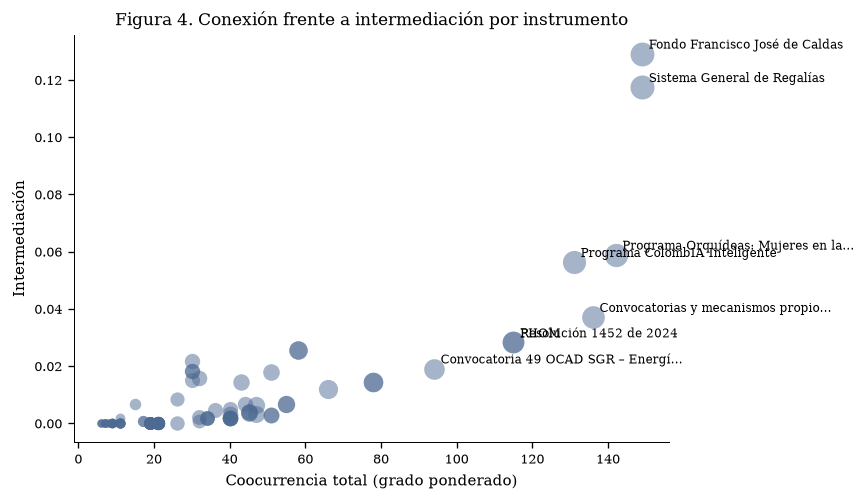

In [13]:
fig, ax = plt.subplots(figsize=(6.4, 4.4))
for n in INST:
    x, y = wdeg[n], btw[n]
    ax.scatter(x, y, s=10 + 10 * PI.degree(n) / 4, color=PALETA[0], alpha=0.5, linewidths=0)
top8 = sorted(INST, key=lambda n: -wdeg[n])[:8]
for n in top8:
    ax.annotate(corto(n, 34), (wdeg[n], btw[n]), xytext=(4, 3),
                textcoords="offset points", fontsize=7)
ax.set_xlabel("Coocurrencia total (grado ponderado)")
ax.set_ylabel("Intermediación")
ax.set_title("Figura 4. Conexión frente a intermediación por instrumento")
fig.savefig(SALIDA / "fig4_conexion_intermediacion.png")
plt.show()

El SGR y el FFJC son los instrumentos más conectados, con una coocurrencia total de 149 cada uno. El FFJC tiene además la mayor intermediación (0,129), así que es el principal puente entre políticas. Ambos tienen la etiqueta *conversión* en la hoja de instrumentos.

Esto hay que tomarlo con cuidado: si la IA vinculó un fondo general a todas las políticas que el texto menciona, el grado está inflado por la clasificación y no por el financiamiento real.

## 7. Pares de instrumentos con más coocurrencia

Los pares más fuertes son aquellos que comparten más políticas.

In [14]:
pares = sorted(PI.edges(data=True), key=lambda e: -e[2]["weight"])[:12]
pd.DataFrame(
    [{"instrumento A": corto(u, 40), "instrumento B": corto(v, 40), "políticas compartidas": d["weight"]}
     for u, v, d in pares]
)

,instrumento A,instrumento B,políticas compartidas
0,Sistema General de Regalías,Programa Orquídeas: Mujeres en la Cienc…,8
1,Fondo Francisco José de Caldas,Programa Orquídeas: Mujeres en la Cienc…,7
2,Fondo Francisco José de Caldas,Sistema General de Regalías,7
3,Fondo Francisco José de Caldas,Convocatorias y mecanismos propios de c…,7
4,Sistema General de Regalías,Programa ColombIA Inteligente,7
5,Sistema General de Regalías,Convocatorias y mecanismos propios de c…,7
6,Programa Orquídeas: Mujeres en la Cienc…,Programa ColombIA Inteligente,7
7,Programa Orquídeas: Mujeres en la Cienc…,Convocatorias y mecanismos propios de c…,7
8,Fondo Francisco José de Caldas,PIIOM,6
9,Fondo Francisco José de Caldas,Resolución 1452 de 2024,6


In [15]:
revisar(
    pares[0][2]["weight"] == max(d["weight"] for _, _, d in PI.edges(data=True)),
    "hay que ordenar las aristas por su peso: e[2] es el diccionario de atributos de la arista.",
)

✅ ¡Bien! Puedes seguir.


## 8. Comunidades de instrumentos

El método de Louvain busca grupos de instrumentos más conectados entre sí que con el resto. La *modularidad* mide qué tan separados quedan esos grupos: va de 0 a 1, y cuanto más alta, más separados. El resultado puede variar un poco de una ejecución a otra. Los nombres de los grupos los ponemos nosotros.

In [16]:
comunidades = sorted(
    nx.community.louvain_communities(PI, weight="weight", seed=SEED),
    key=len, reverse=True,
)
modularidad = nx.community.modularity(PI, comunidades, weight="weight")
comm_id = {n: i for i, c in enumerate(comunidades) for n in c}

print(f"{len(comunidades)} comunidades, modularidad = {modularidad:.3f}")
for i, c in enumerate(comunidades):
    print(f"  C{i}: {len(c)} instrumentos")

5 comunidades, modularidad = 0.243
  C0: 29 instrumentos
  C1: 21 instrumentos
  C2: 16 instrumentos
  C3: 15 instrumentos
  C4: 12 instrumentos


In [17]:
revisar(
    len(comunidades) > 1 and sum(len(c) for c in comunidades) == 93 and modularidad > 0,
    "el método de Louvain está en nx.community.louvain_communities.",
)

✅ ¡Bien! Puedes seguir.


La modularidad (0,24) indica una estructura moderada: hay grupos reconocibles, pero se solapan bastante.

La figura muestra los 30 instrumentos con más coocurrencia, coloreados por comunidad. Solo se dibujan las aristas de peso 2 o más, y el grosor crece con el peso.

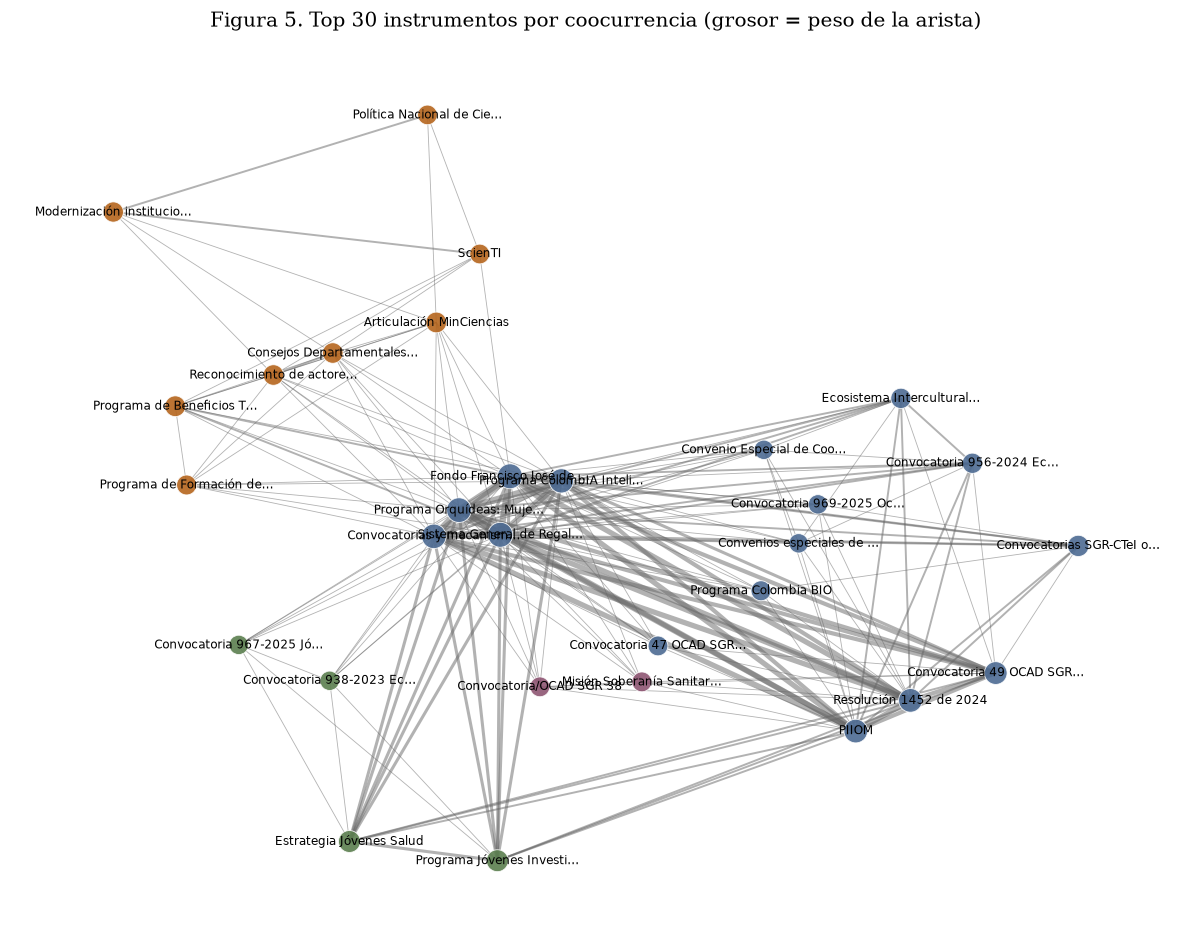

In [18]:
top30 = sorted(INST, key=lambda n: -wdeg[n])[:30]
H = PI.subgraph(top30).copy()
H.remove_edges_from([(u, v) for u, v, d in H.edges(data=True) if d["weight"] < 2])

# Kamada-Kawai reparte mejor que spring_layout los nodos del centro, que están muy conectados.
pos_h = nx.kamada_kawai_layout(H, weight="weight")

fig, ax = plt.subplots(figsize=(10, 8))

# Grosor de la arista: el peso llevado a un rango visual de 0,5 a 4,5
pesos = [d["weight"] for _, _, d in H.edges(data=True)]
min_w, max_w = min(pesos), max(pesos)
min_ancho, max_ancho = 0.5, 4.5
anchos = [
    min_ancho + (max_ancho - min_ancho) * ((w - min_w) / (max_w - min_w))
    if max_w > min_w else min_ancho
    for w in pesos
]
nx.draw_networkx_edges(H, pos_h, width=anchos, alpha=0.5, edge_color="#666666", ax=ax)

# Tamaño del nodo con raíz cuadrada, para que los grandes no tapen a los pequeños
node_sizes = [40 + 15 * np.sqrt(wdeg[n]) for n in H.nodes()]
nx.draw_networkx_nodes(
    H, pos_h,
    node_size=node_sizes,
    node_color=[PALETA[comm_id[n] % len(PALETA)] for n in H.nodes()],
    alpha=0.9, linewidths=0.5, edgecolors="white", ax=ax,
)

etiquetas = {n: corto(n, 25) for n in H.nodes()}
nx.draw_networkx_labels(H, pos_h, labels=etiquetas, font_size=7, ax=ax)

ax.axis("off")
ax.set_title("Figura 5. Top 30 instrumentos por coocurrencia (grosor = peso de la arista)", fontsize=12)
plt.tight_layout()
fig.savefig(SALIDA / "fig5_comunidades.png", dpi=300)
plt.show()

Lectura aproximada de los grupos, inferida de los nombres:

- **Territorial y bioeconómica:** convenios con SINCHI, CRIC y la Mesa Permanente de Concertación.
- **Núcleo institucional y PIIOM:** Decreto 1666, CONACTI, CODECTI y CONPES 4069.
- **Salud y ecosistemas científicos:** convocatorias de 2022 en salud pública y salud mental.
- **Talento y becas:** doctorados, CRIIE y el Premio Otto de Greiff.
- **Internacional e IA:** Comité Asesor de IA, Hoja de Ruta de IA y convenios internacionales.

## 9. Red de coocurrencia de políticas

Proyectamos la bipartita sobre las políticas. Dos políticas quedan conectadas si comparten instrumentos, y el peso es el número de instrumentos compartidos.

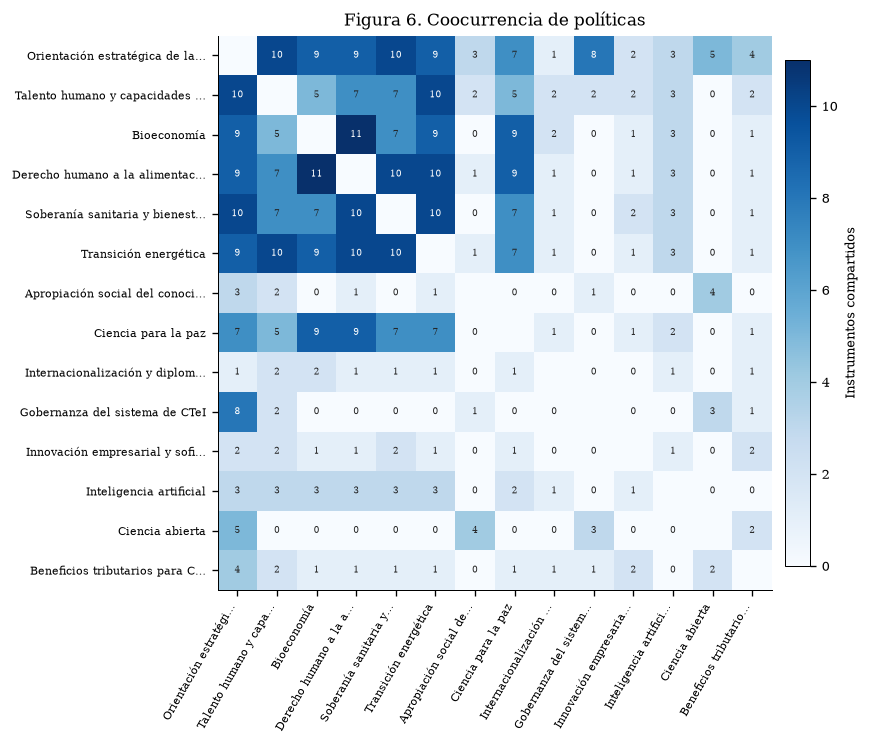

In [19]:
PP = bp.weighted_projected_graph(B, POL)
orden_pol = sorted(POL, key=lambda p: -B.degree(p))
M = nx.to_pandas_adjacency(PP, nodelist=orden_pol, dtype=float)
Mv = M.to_numpy(copy=True)  # la diagonal no se usa en el mapa de calor

fig, ax = plt.subplots(figsize=(6.8, 6.0))
im = ax.imshow(Mv, cmap="Blues", vmin=0)
ax.set_xticks(range(len(orden_pol)))
ax.set_yticks(range(len(orden_pol)))
ax.set_xticklabels([corto(p, 22) for p in orden_pol], rotation=60, ha="right", fontsize=6.5)
ax.set_yticklabels([corto(p, 30) for p in orden_pol], fontsize=6.5)
for i in range(len(orden_pol)):
    for j in range(len(orden_pol)):
        if i != j:
            ax.text(j, i, int(Mv[i, j]), ha="center", va="center", fontsize=5.5,
                    color="white" if Mv[i, j] > 7 else "#222222")
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
cb.set_label("Instrumentos compartidos", fontsize=8)
ax.set_title("Figura 6. Coocurrencia de políticas")
fig.savefig(SALIDA / "fig6_coocurrencia_politicas.png")
plt.show()

In [20]:
revisar(
    PP.number_of_nodes() == 14 and PP.number_of_edges() == 65,
    "esta vez la proyección va sobre el conjunto de políticas (POL).",
)

✅ ¡Bien! Puedes seguir.


La red de políticas tiene 65 aristas y una densidad de 0,714. Es muy densa, así que distingue poco entre políticas. Los pares más fuertes son DHA–Bioeconomía (11 instrumentos compartidos), Soberanía sanitaria–DHA (10) y Soberanía sanitaria–Orientación estratégica (10).

## 10. Exportación

Guardamos las dos redes en GraphML, un formato que abren programas de redes como Gephi. En Colab, la última celda descarga todo en un .zip.

In [21]:
nx.write_graphml(PI, SALIDA / "proyeccion_instrumentos.graphml")
nx.write_graphml(B, SALIDA / "bipartita_instrumentos_politicas.graphml")
tabla_top.to_csv(SALIDA / "top15_instrumentos.csv", index=False)
print("Archivos guardados en", SALIDA)

Archivos guardados en salidas


In [22]:
if EN_COLAB:
    import shutil
    zip_salidas = shutil.make_archive("salidas", "zip", SALIDA)
    files.download(zip_salidas)

## 11. Conclusiones

**Lo que muestra la red:**

- La red bipartita es conexa, con 107 nodos, 201 aristas y ningún instrumento aislado.
- SGR y FFJC son los instrumentos más conectados (coocurrencia 149 cada uno). FFJC tiene además la mayor intermediación (0,129).
- Los instrumentos más conectados son casi todos de financiamiento (tesoro).
- La red de políticas es muy densa (0,714), así que la coocurrencia entre políticas aporta poca información.

**Inferencias que requieren verificación:**

- Los fondos generales pueden estar sobreasignados a varias políticas por la forma en que se extrajo la columna "Políticas a las que sirve".
- La estratificación puede estar inflada si hay instrumentos renombrados entre informes.
- Las comunidades reflejan más un patrón territorial y de salud que uno por política declarada.

Para verificar, conviene revisar los informes en las páginas citadas de los instrumentos con mayor grado y de los casos marcados como terminación.